# 02 · Manifold — principal-curve trajectory (cell-cycle-regressed manifold)

Chan 2021's malignant manifold is **non-branching**: the gastrulation / somitogenesis / neural-crest
developmental signatures form a single monotone gradient (Gast & pSom co-vary; Crest is the
opposite, terminal end) rather than a hub radiating to discrete subtypes. The correct topology is
therefore a **principal curve** (ElPiGraph, non-branching by construction), fit on the
cell-cycle-regressed joint embedding produced in 01 — we do **not** re-embed here (that embedding is
already near-isotropic; re-embedding an anisotropic compartment fabricates folds).

**Confound handled upstream (derived, not inherited).** SCLC's dominant axis is proliferation; a
curve on the un-regressed embedding tracks cell cycle (ρ≈−0.79) and inverts the developmental order.
01 removed that confound by regressing the publication's cell-cycle scores out of the integrated
representation. Here we confirm the fitted curve's pseudotime is **decorrelated from cell cycle**
(ρ≈0) while ordering the developmental signatures coherently: Gast and pSom both decline from the
Gast/pSom-high root and the neural-crest signature rises to the terminus. Deliverable:
`manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells stay on their 01 (cell-cycle-regressed) embedding coordinates — no re-embedding. The three
embryonic signatures are scored against the shared **union** control pool and graph-smoothed to read
geography rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold (cc-regressed embedding):', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

malignant manifold (cc-regressed embedding): 50886 cells
UMAP aspect ratio (major/minor std): 1.04
Gast: 80/81 genes present
pSom: 96/98 genes present
Crest: 104/104 genes present


### Developmental geography — the non-branching signature
On the cc-regressed manifold the smoothed signatures form one axis: Gast and pSom co-vary
positively, both oppose Crest. This is the shared-gradient (non-branching) pattern, not a hub
radiating into two competing arms.

In [4]:
print('smoothed spatial correlations:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')

smoothed spatial correlations:
  Gast_sm vs pSom_sm: r = +0.73
  Crest_sm vs Gast_sm: r = -0.71
  Crest_sm vs pSom_sm: r = -0.88


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone. A node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. `epg_mu=100` is strong bending regularisation; `Nodes=30` is
scaled up from the small-dataset default (Lee 2020 used 20 on ~1k cells) for this ~51k-cell
manifold while remaining fold-free.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=30, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print('curve: %d tips, %d forks | fold self-approach ratio = %.2f (>1 = fold-free)' % (tips, forks, sa))
assert forks == 0 and sa > 1, 'topology check failed (fork or fold detected)'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.06 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin.
Pseudotime then flows to the neural-crest terminus, and we confirm it is decorrelated from cell
cycle (confound handled in 01).

In [6]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, info[tp][0], info[tp][1], info[tp][2]))
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, adata.obs[sname]); print('  %s: rho=%+.3f p=%.1e' % (sname, rho, p))

tip 0: Gast=+0.0431 pSom=+0.1257 Crest=-0.0917
tip 2: Gast=+0.0350 pSom=+0.1042 Crest=-0.0830
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.243 p=0.0e+00
  pSom_sm: rho=-0.451 p=0.0e+00
  Crest_sm: rho=+0.235 p=0.0e+00
  cyc_score: rho=+0.003 p=4.9e-01


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (axis choice + sign flip, no rotation). Pick the raw axis
most correlated with pseudotime as horizontal, then flip so low pseudotime lands on the left.

In [7]:
xy = adata.obsm['X_umap'].copy(); t = adata.obs['t'].values
cx = abs(np.corrcoef(xy[:,0], t)[0,1]); cy = abs(np.corrcoef(xy[:,1], t)[0,1])
xyr = np.column_stack([xy[:,1], xy[:,0]]) if cy > cx else np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, 'pseudotime not oriented left->right'
adata.obsm['X_umap_lin'] = xyr
print('orientation: corr(x_lin, pseudotime) = %+.2f (left->right)' % r)

orientation: corr(x_lin, pseudotime) = +0.70 (left->right)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf | cells: 50886


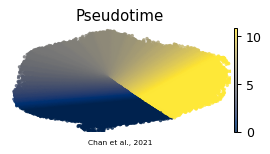

In [8]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Chan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf | cells:', adata.shape[0])